# 03 — MVTec: surrogate benchmarking and training

Benchmarks 13 candidate regressors (CatBoost + 12 scikit-learn/XGBoost models) on the
surrogate-ready dataset from notebook 02 using an 80/20 stratified split, then fixes CatBoost
as the operational surrogate (Section 3.4) with the paper's exact hyperparameters (5000
iterations, learning rate 0.05, depth 8, `l2_leaf_reg=3.0`, early stopping after 200 rounds).
Produces the development-split rows of **Table 2** (Section 4.3) — CatBoost is selected for its
native categorical handling and built-in Shapley/feature-importance tooling, not because it
topped the RMSE benchmark (HistGradientBoosting and, on this log, XGBoost are narrowly
competitive; see the printed rationale in this notebook).

The *primary* generalisation estimate reported in the paper (5-fold GroupKFold cross-validation
grouped by exact configuration signature, R2 = 0.995) is **not** computed here — it lives in
`shared/07_cross_dataset_revision_analysis.ipynb` (section S10), which needs both datasets'
surrogates loaded together.

Saves `surrogate_pkl_cfs_metadata/mvtec_surrogate_catboost.cbm` and
`mvtec_surrogate_metadata.json`, consumed by notebook 04.

**Known caveat (unmodified from source):** the sklearn model zoo tries to import XGBoost; the
archived benchmark table includes an XGBoost row, but `xgboost` is not among the paper's pinned
Section 4.2 dependencies. If XGBoost is not installed, this cell degrades gracefully (one fewer
benchmark row) and the CatBoost result is unaffected.


In [1]:
# ============================================================
# MVTec 4-class PatchCore surrogate modelling
# ============================================================

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    AdaBoostRegressor,
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import BayesianRidge, ElasticNet, HuberRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from catboost import CatBoostRegressor, Pool

try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except Exception:
    HAS_XGBOOST = False
    XGBRegressor = None

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 180)

CWD = Path.cwd()
print("Current working directory:")
print(CWD)

DATA_FILENAME = "mvtec_4class_patchcore_surrogate_dataset.csv"

candidate_paths = [
    CWD / "surrogate_ready_dataset" / DATA_FILENAME,
    CWD / "hpo_mvtec_4class" / "surrogate_ready_dataset" / DATA_FILENAME,
    CWD.parent / "surrogate_ready_dataset" / DATA_FILENAME,
    CWD.parent / "hpo_mvtec_4class" / "surrogate_ready_dataset" / DATA_FILENAME,
]

# Recursive search from current directory and parent
for base in [CWD, CWD.parent]:
    try:
        candidate_paths.extend(base.rglob(DATA_FILENAME))
    except Exception:
        pass

seen = set()
candidate_paths_unique = []
for p in candidate_paths:
    p = p.resolve()
    if p not in seen:
        seen.add(p)
        candidate_paths_unique.append(p)

existing = []

print("\nCandidate dataset paths:")
for p in candidate_paths_unique:
    exists = p.exists()
    print(f"- exists={exists:<5} | {p}")
    if exists:
        existing.append(p)

if not existing:
    raise FileNotFoundError(
        "Could not find mvtec_4class_patchcore_surrogate_dataset.csv. "
        "Run the MVTec preprocessing notebook first."
    )

DATA_PATH = existing[0]
ROOT = DATA_PATH.parent.parent

OUT_DIR = ROOT / "surrogate_pkl_cfs_metadata"
FIG_DIR = ROOT / "figures_surrogate"
TABLE_DIR = ROOT / "tables_surrogate"

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("\nSelected dataset:")
print(DATA_PATH)

print("\nOutput directories:")
print("OUT_DIR:", OUT_DIR)
print("FIG_DIR:", FIG_DIR)
print("TABLE_DIR:", TABLE_DIR)

Current working directory:
/home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec

Candidate dataset paths:
- exists=1     | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv
- exists=0     | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/hpo_mvtec_4class/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv
- exists=0     | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv
- exists=0     | /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/hpo_mvtec_4class/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv

Selected dataset:
/h

In [2]:
# ============================================================
# 1. Load surrogate-ready dataset
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)

display(df.head())
display(df.describe(include="all").T)

Loaded: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv
Shape: (9976, 14)


,value,params_backbone,params_batch_size,params_center_crop_key,params_coreset_sampling_ratio,params_image_size_key,params_layers_key,params_max_patches_per_image,params_num_neighbors,params_pre_trained,params_reduction,params_soft_corruption_level,params_soft_review_budget,params_soft_train_fraction
0,0.569961,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
1,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50
2,0.288997,resnet34,8,0.875,0.099,320,l2,128,26,True,mean,none,0.11,0.61
3,0.332794,resnet34,8,0.875,0.003,256,l2_l3,512,25,True,max,strong,0.22,0.66
4,0.564978,wide_resnet50_2,8,0.875,0.055,256,l3,1024,25,True,max,none,0.33,0.50


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
value,9976.0,NaN,NaN,NaN,0.524907,0.228218,0.015625,0.347519,0.562076,0.732452,0.820249
params_backbone,9976,4,wide_resnet50_2,6917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
params_batch_size,9976.0,NaN,NaN,NaN,14.428228,3.178793,8.0,16.0,16.0,16.0,16.0
params_center_crop_key,9976,2,0.875,7994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
params_coreset_sampling_ratio,9976.0,NaN,NaN,NaN,0.035027,0.02344,0.001,0.021,0.027,0.039,0.101
params_image_size_key,9976.0,NaN,NaN,NaN,260.644747,25.942224,224.0,256.0,256.0,256.0,320.0
params_layers_key,9976,4,l2_l3,6920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
params_max_patches_per_image,9976.0,NaN,NaN,NaN,803.284683,345.438802,128.0,512.0,1024.0,1024.0,1024.0
params_num_neighbors,9976.0,NaN,NaN,NaN,7.581997,8.646676,1.0,2.0,3.0,12.0,30.0
params_pre_trained,9976,2,True,7948,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# ============================================================
# 2. Target and feature schema
# ============================================================

TARGET = "value"

categorical_features = [
    "params_backbone",
    "params_batch_size",
    "params_center_crop_key",
    "params_image_size_key",
    "params_layers_key",
    "params_max_patches_per_image",
    "params_pre_trained",
    "params_reduction",
    "params_soft_corruption_level",
]

numeric_features = [
    "params_coreset_sampling_ratio",
    "params_num_neighbors",
    "params_soft_review_budget",
    "params_soft_train_fraction",
]

FEATURES = categorical_features + numeric_features

missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

df = df[[TARGET] + FEATURES].copy()

# Ensure stable dtypes
for c in categorical_features:
    df[c] = df[c].astype(str)

for c in numeric_features + [TARGET]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

before = len(df)
df = df.dropna(subset=[TARGET] + FEATURES).reset_index(drop=True)
after = len(df)

print("Rows before dropna:", before)
print("Rows after dropna:", after)
print("Dropped rows:", before - after)

print("\nTarget summary:")
display(df[TARGET].describe())

print("\nFeature groups:")
print("Categorical:", len(categorical_features), categorical_features)
print("Numeric:", len(numeric_features), numeric_features)

assert set(FEATURES) == set(df.drop(columns=[TARGET]).columns), "Feature list mismatch"

Rows before dropna: 9976
Rows after dropna: 9976
Dropped rows: 0

Target summary:


count    9976.000000
mean        0.524907
std         0.228218
min         0.015625
25%         0.347519
50%         0.562076
75%         0.732452
max         0.820249
Name: value, dtype: float64


Feature groups:
Categorical: 9 ['params_backbone', 'params_batch_size', 'params_center_crop_key', 'params_image_size_key', 'params_layers_key', 'params_max_patches_per_image', 'params_pre_trained', 'params_reduction', 'params_soft_corruption_level']
Numeric: 4 ['params_coreset_sampling_ratio', 'params_num_neighbors', 'params_soft_review_budget', 'params_soft_train_fraction']


In [4]:
# ============================================================
# 3. Train/test split
# ============================================================

X = df.drop(columns=[TARGET])
y = df[TARGET]

def make_regression_stratification(y, n_bins=10):
    """
    Robust stratification for regression targets.
    Uses quantile bins; falls back to None if bins are not feasible.
    """
    y_series = pd.Series(y).reset_index(drop=True)

    try:
        bins = pd.qcut(y_series, q=n_bins, duplicates="drop")
        strat = bins.astype(str)

        counts = strat.value_counts()
        if counts.min() < 2:
            print("Some stratification bins have fewer than 2 samples. Falling back to no stratification.")
            return None

        return strat
    except Exception as exc:
        print("Could not create regression stratification:", exc)
        return None

strat = make_regression_stratification(y, n_bins=10)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    shuffle=True,
    stratify=strat,
)

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)

print("\nTarget summary by split:")
split_summary = pd.DataFrame({
    "train": y_train.describe(),
    "test": y_test.describe(),
})
display(split_summary)

Train: (7980, 13) (7980,)
Test:  (1996, 13) (1996,)

Target summary by split:


,train,test
count,7980.000000,1996.000000
mean,0.524598,0.526142
std,0.228562,0.226890
min,0.024306,0.015625
25%,0.347519,0.347519
50%,0.562076,0.562076
75%,0.732452,0.732563
max,0.820249,0.820249


In [5]:
# ============================================================
# 4. Preprocessing for sklearn models
# ============================================================

def make_one_hot_encoder():
    """
    Compatibility helper for different sklearn versions.
    """
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocess = ColumnTransformer(
    transformers=[
        ("cat", make_one_hot_encoder(), categorical_features),
        ("num", "passthrough", numeric_features),
    ],
    remainder="drop",
)

print("Preprocessor ready.")

Preprocessor ready.


In [6]:
# ============================================================
# 5. Benchmark utilities
# ============================================================

def eval_regression(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    return rmse, mae, r2


def benchmark(models, X_train, y_train, X_test, y_test, preprocess):
    rows = []
    fitted = {}

    for name, est in models.items():
        print(f"\nTraining {name}...")

        pipe = Pipeline([
            ("prep", preprocess),
            ("model", clone(est)),
        ])

        try:
            t0 = time.time()
            pipe.fit(X_train, y_train)
            fit_sec = time.time() - t0

            y_pred = pipe.predict(X_test)
            rmse, mae, r2 = eval_regression(y_test, y_pred)

            rows.append({
                "model": name,
                "rmse": rmse,
                "mae": mae,
                "r2": r2,
                "fit_sec": fit_sec,
                "status": "ok",
                "error": "",
            })

            fitted[name] = pipe

            print(f"{name}: RMSE={rmse:.6f}, MAE={mae:.6f}, R2={r2:.6f}, fit_sec={fit_sec:.2f}")

        except Exception as exc:
            rows.append({
                "model": name,
                "rmse": np.nan,
                "mae": np.nan,
                "r2": np.nan,
                "fit_sec": np.nan,
                "status": "failed",
                "error": str(exc),
            })

            print(f"{name} failed:", exc)

    results = (
        pd.DataFrame(rows)
        .sort_values(["status", "rmse", "mae"], ascending=[True, True, True])
        .reset_index(drop=True)
    )

    return results, fitted

In [7]:
# ============================================================
# 6. Model zoo
# ============================================================

models = {
    "HistGBDT": HistGradientBoostingRegressor(random_state=SEED),
    "RandomForest": RandomForestRegressor(
        n_estimators=400,
        random_state=SEED,
        n_jobs=-1,
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=800,
        random_state=SEED,
        n_jobs=-1,
    ),
    "GBDT": GradientBoostingRegressor(random_state=SEED),
    "AdaBoost": AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=4, random_state=SEED),
        n_estimators=400,
        learning_rate=0.05,
        random_state=SEED,
    ),
    "DecisionTree": DecisionTreeRegressor(random_state=SEED),
    "KNN": KNeighborsRegressor(n_neighbors=25, weights="distance"),
    "SVR(RBF)": SVR(C=10.0, epsilon=0.02, gamma="scale"),
    "BayesianRidge": BayesianRidge(),
    "ElasticNet": ElasticNet(alpha=1e-3, l1_ratio=0.2, random_state=SEED),
    "Huber": HuberRegressor(),
}

if HAS_XGBOOST:
    models["XGBoost"] = XGBRegressor(
        n_estimators=800,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=-1,
    )

print("Models to benchmark:")
for name in models:
    print("-", name)

Models to benchmark:
- HistGBDT
- RandomForest
- ExtraTrees
- GBDT
- AdaBoost
- DecisionTree
- KNN
- SVR(RBF)
- BayesianRidge
- ElasticNet
- Huber
- XGBoost


In [8]:
# ============================================================
# 7. Run sklearn benchmark
# ============================================================

results, fitted_pipes = benchmark(
    models=models,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    preprocess=preprocess,
)

display(results)

benchmark_path = TABLE_DIR / "mvtec_surrogate_model_benchmark_sklearn.csv"
results.to_csv(benchmark_path, index=False)

print("Saved:", benchmark_path)


Training HistGBDT...
HistGBDT: RMSE=0.014726, MAE=0.007935, R2=0.995785, fit_sec=0.37

Training RandomForest...
RandomForest: RMSE=0.017585, MAE=0.008609, R2=0.993990, fit_sec=0.49

Training ExtraTrees...
ExtraTrees: RMSE=0.017592, MAE=0.008716, R2=0.993985, fit_sec=0.66

Training GBDT...
GBDT: RMSE=0.017022, MAE=0.009453, R2=0.994369, fit_sec=0.65

Training AdaBoost...
AdaBoost: RMSE=0.028218, MAE=0.022754, R2=0.984525, fit_sec=4.07

Training DecisionTree...
DecisionTree: RMSE=0.024203, MAE=0.011624, R2=0.988615, fit_sec=0.04

Training KNN...
KNN: RMSE=0.109729, MAE=0.057989, R2=0.765992, fit_sec=0.01

Training SVR(RBF)...
SVR(RBF): RMSE=0.039203, MAE=0.031210, R2=0.970130, fit_sec=3.03

Training BayesianRidge...
BayesianRidge: RMSE=0.042565, MAE=0.034064, R2=0.964788, fit_sec=0.03

Training ElasticNet...
ElasticNet: RMSE=0.043806, MAE=0.033695, R2=0.962705, fit_sec=0.03

Training Huber...
Huber: RMSE=0.043793, MAE=0.033752, R2=0.962726, fit_sec=0.27

Training XGBoost...
XGBoost: RMS

,model,rmse,mae,r2,fit_sec,status,error
0,HistGBDT,0.014726,0.007935,0.995785,0.374586,ok,
1,XGBoost,0.015273,0.007893,0.995467,0.606794,ok,
2,GBDT,0.017022,0.009453,0.994369,0.647187,ok,
3,RandomForest,0.017585,0.008609,0.993990,0.486442,ok,
4,ExtraTrees,0.017592,0.008716,0.993985,0.656705,ok,
5,DecisionTree,0.024203,0.011624,0.988615,0.039608,ok,
6,AdaBoost,0.028218,0.022754,0.984525,4.070263,ok,
7,SVR(RBF),0.039203,0.031210,0.970130,3.026857,ok,
8,BayesianRidge,0.042565,0.034064,0.964788,0.033029,ok,
9,Huber,0.043793,0.033752,0.962726,0.269265,ok,


Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_surrogate/mvtec_surrogate_model_benchmark_sklearn.csv


In [9]:
# ============================================================
# 8. CatBoost native categorical surrogate
# ============================================================

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for c in categorical_features:
    X_train_cb[c] = X_train_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

cat_features_idx = [X_train_cb.columns.get_loc(c) for c in categorical_features]

print("CatBoost categorical feature indices:", cat_features_idx)
print("CatBoost categorical features:", categorical_features)

cb = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="RMSE",
    iterations=5000,
    learning_rate=0.05,
    depth=8,
    l2_leaf_reg=3.0,
    random_seed=SEED,
    verbose=200,
)

t0 = time.time()

cb.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features_idx,
    eval_set=(X_test_cb, y_test),
    use_best_model=True,
    early_stopping_rounds=200,
)

cb_fit_sec = time.time() - t0

print("CatBoost fit_sec:", cb_fit_sec)
print("Best iteration:", cb.get_best_iteration())

CatBoost categorical feature indices: [0, 1, 2, 3, 4, 5, 6, 7, 8]
CatBoost categorical features: ['params_backbone', 'params_batch_size', 'params_center_crop_key', 'params_image_size_key', 'params_layers_key', 'params_max_patches_per_image', 'params_pre_trained', 'params_reduction', 'params_soft_corruption_level']
0:	learn: 0.2178460	test: 0.2161322	best: 0.2161322 (0)	total: 53.8ms	remaining: 4m 28s
200:	learn: 0.0136320	test: 0.0169163	best: 0.0169163 (200)	total: 1.53s	remaining: 36.5s
400:	learn: 0.0112407	test: 0.0160531	best: 0.0160531 (400)	total: 2.92s	remaining: 33.5s
600:	learn: 0.0096755	test: 0.0156307	best: 0.0156307 (600)	total: 4.35s	remaining: 31.8s
800:	learn: 0.0084907	test: 0.0154509	best: 0.0154472 (797)	total: 5.81s	remaining: 30.4s
1000:	learn: 0.0074409	test: 0.0153158	best: 0.0153153 (999)	total: 7.26s	remaining: 29s
1200:	learn: 0.0065904	test: 0.0152042	best: 0.0152022 (1198)	total: 8.71s	remaining: 27.5s
1400:	learn: 0.0059391	test: 0.0151425	best: 0.0151354 

In [10]:
# ============================================================
# 9. Evaluate CatBoost and final benchmark table
# ============================================================

y_pred_cb = cb.predict(X_test_cb)

rmse_cb, mae_cb, r2_cb = eval_regression(y_test, y_pred_cb)

print(f"CatBoost(native) -> RMSE: {rmse_cb:.6f} | MAE: {mae_cb:.6f} | R2: {r2_cb:.6f}")

cb_row = pd.DataFrame([{
    "model": "CatBoost(native)",
    "rmse": rmse_cb,
    "mae": mae_cb,
    "r2": r2_cb,
    "fit_sec": cb_fit_sec,
    "status": "ok",
    "error": "",
}])

results_all = (
    pd.concat([results, cb_row], ignore_index=True)
    .sort_values(["rmse", "mae"], ascending=[True, True])
    .reset_index(drop=True)
)

display(results_all)

best_overall = results_all.loc[results_all["status"] == "ok"].iloc[0]["model"]
print("Best overall model by RMSE:", best_overall)

results_all_path = TABLE_DIR / "mvtec_surrogate_model_benchmark_all.csv"
results_all.to_csv(results_all_path, index=False)

print("Saved:", results_all_path)

CatBoost(native) -> RMSE: 0.015053 | MAE: 0.007954 | R2: 0.995596


,model,rmse,mae,r2,fit_sec,status,error
0,HistGBDT,0.014726,0.007935,0.995785,0.374586,ok,
1,CatBoost(native),0.015053,0.007954,0.995596,19.575429,ok,
2,XGBoost,0.015273,0.007893,0.995467,0.606794,ok,
3,GBDT,0.017022,0.009453,0.994369,0.647187,ok,
4,RandomForest,0.017585,0.008609,0.993990,0.486442,ok,
5,ExtraTrees,0.017592,0.008716,0.993985,0.656705,ok,
6,DecisionTree,0.024203,0.011624,0.988615,0.039608,ok,
7,AdaBoost,0.028218,0.022754,0.984525,4.070263,ok,
8,SVR(RBF),0.039203,0.031210,0.970130,3.026857,ok,
9,BayesianRidge,0.042565,0.034064,0.964788,0.033029,ok,


Best overall model by RMSE: HistGBDT
Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_surrogate/mvtec_surrogate_model_benchmark_all.csv


In [11]:
# ============================================================
# 10. Select final surrogate
# ============================================================

FINAL_MODEL = "CatBoost(native)"

print("Selected final surrogate:", FINAL_MODEL)
print(
    "Reason: native categorical handling, stable mixed-type configuration support, "
    "and direct compatibility with the counterfactual pipeline."
)

Selected final surrogate: CatBoost(native)
Reason: native categorical handling, stable mixed-type configuration support, and direct compatibility with the counterfactual pipeline.


In [12]:
# ============================================================
# 11. CatBoost diagnostics
# ============================================================

y_true = y_test.to_numpy()
y_pred = np.asarray(cb.predict(X_test_cb))

residuals = y_true - y_pred
abs_err = np.abs(residuals)

diagnostics_df = pd.DataFrame({
    "test_index": X_test.index,
    "y_true": y_true,
    "y_pred": y_pred,
    "residual": residuals,
    "abs_error": abs_err,
})

diagnostics_path = TABLE_DIR / "mvtec_catboost_test_predictions.csv"
diagnostics_df.to_csv(diagnostics_path, index=False)

print("Saved:", diagnostics_path)

print("CatBoost(native) test diagnostics")
print("y_true min/max:", float(np.min(y_true)), float(np.max(y_true)))
print("y_pred min/max:", float(np.min(y_pred)), float(np.max(y_pred)))
print("residual mean:", float(np.mean(residuals)))
print("residual std:", float(np.std(residuals)))

display(diagnostics_df.head())

Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_surrogate/mvtec_catboost_test_predictions.csv
CatBoost(native) test diagnostics
y_true min/max: 0.015625 0.8202491952491952
y_pred min/max: 0.036806332622152216 0.8081900301036276
residual mean: -0.0006348556370037756
residual std: 0.01503922505771523


,test_index,y_true,y_pred,residual,abs_error
0,3462,0.497047,0.501791,-0.004745,0.004745
1,2587,0.439709,0.452532,-0.012823,0.012823
2,7292,0.732346,0.727085,0.005260,0.005260
3,2451,0.409978,0.472179,-0.062202,0.062202
4,9629,0.434384,0.434911,-0.000527,0.000527


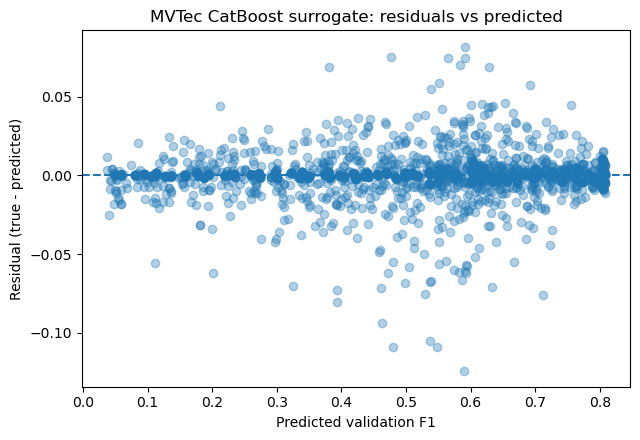

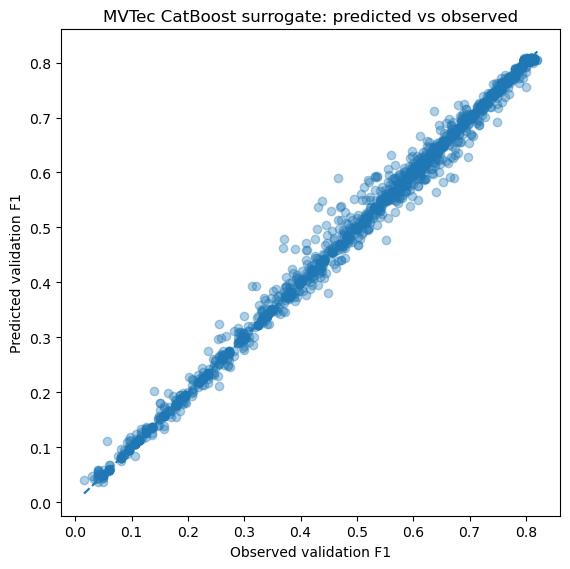

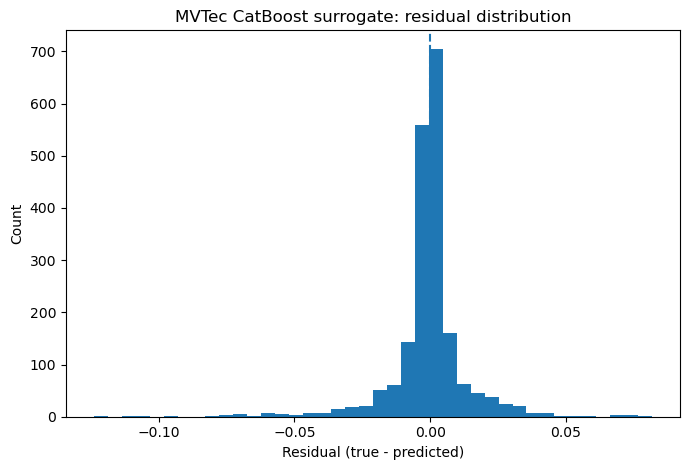

In [13]:
# ============================================================
# 12. Diagnostic plots
# ============================================================

# Residuals vs predicted
plt.figure(figsize=(6.5, 4.5))
plt.scatter(y_pred, residuals, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted validation F1")
plt.ylabel("Residual (true - predicted)")
plt.title("MVTec CatBoost surrogate: residuals vs predicted")
plt.tight_layout()
plt.savefig(FIG_DIR / "mvtec_catboost_residuals_vs_predicted.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mvtec_catboost_residuals_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()


# Predicted vs true
plt.figure(figsize=(5.8, 5.8))
plt.scatter(y_true, y_pred, alpha=0.35)
lims = [
    min(float(np.min(y_true)), float(np.min(y_pred))),
    max(float(np.max(y_true)), float(np.max(y_pred))),
]
plt.plot(lims, lims, "--")
plt.xlabel("Observed validation F1")
plt.ylabel("Predicted validation F1")
plt.title("MVTec CatBoost surrogate: predicted vs observed")
plt.tight_layout()
plt.savefig(FIG_DIR / "mvtec_catboost_predicted_vs_observed.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mvtec_catboost_predicted_vs_observed.png", dpi=300, bbox_inches="tight")
plt.show()


# Residual histogram
plt.figure(figsize=(7.0, 4.8))
plt.hist(residuals, bins=40)
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (true - predicted)")
plt.ylabel("Count")
plt.title("MVTec CatBoost surrogate: residual distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "mvtec_catboost_residual_distribution.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mvtec_catboost_residual_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

,bin,y_true_mean,y_pred_mean,n
0,"(0.0358, 0.178]",0.111073,0.112406,200
1,"(0.178, 0.298]",0.243817,0.243640,201
2,"(0.298, 0.398]",0.350809,0.352979,198
3,"(0.398, 0.495]",0.444947,0.446588,200
4,"(0.495, 0.565]",0.525830,0.528563,199
5,"(0.565, 0.624]",0.596344,0.595830,200
6,"(0.624, 0.694]",0.656083,0.655651,199
7,"(0.694, 0.773]",0.731289,0.731055,200
8,"(0.773, 0.804]",0.797821,0.797513,200
9,"(0.804, 0.808]",0.805104,0.805262,199


Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_surrogate/mvtec_catboost_calibration_by_predicted_quantile.csv


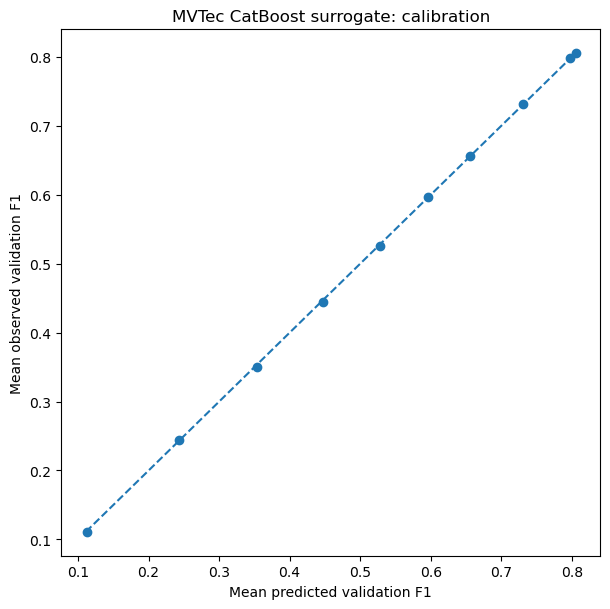

In [14]:
# ============================================================
# 14. Calibration by predicted quantiles
# ============================================================

cal_bins = pd.qcut(pd.Series(y_pred), q=10, duplicates="drop")

cal = (
    pd.DataFrame({
        "bin": cal_bins.astype(str),
        "y_true": y_true,
        "y_pred": y_pred,
    })
    .groupby("bin")
    .agg(
        y_true_mean=("y_true", "mean"),
        y_pred_mean=("y_pred", "mean"),
        n=("y_true", "size"),
    )
    .reset_index()
)

display(cal)

cal_path = TABLE_DIR / "mvtec_catboost_calibration_by_predicted_quantile.csv"
cal.to_csv(cal_path, index=False)

print("Saved:", cal_path)

plt.figure(figsize=(6.2, 6.2))
plt.scatter(cal["y_pred_mean"], cal["y_true_mean"])
lims = [
    min(float(cal["y_pred_mean"].min()), float(cal["y_true_mean"].min())),
    max(float(cal["y_pred_mean"].max()), float(cal["y_true_mean"].max())),
]
plt.plot(lims, lims, "--")
plt.xlabel("Mean predicted validation F1")
plt.ylabel("Mean observed validation F1")
plt.title("MVTec CatBoost surrogate: calibration")
plt.tight_layout()
plt.savefig(FIG_DIR / "mvtec_catboost_calibration.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mvtec_catboost_calibration.png", dpi=300, bbox_inches="tight")
plt.show()

Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/figures_surrogate/mvtec_surrogate_fidelity.pdf
Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/figures_surrogate/mvtec_surrogate_fidelity.png


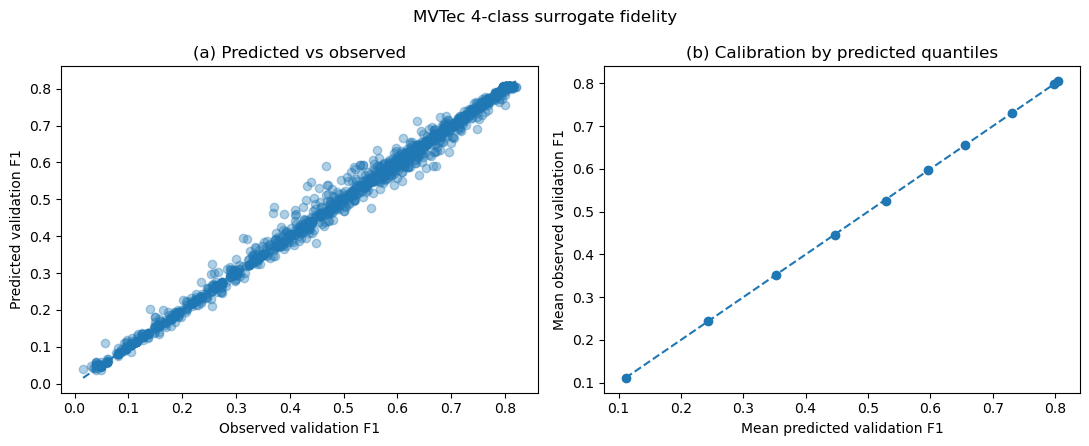

In [15]:
# ============================================================
# 15. Paper-ready surrogate fidelity figure
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel A: predicted vs observed
axes[0].scatter(y_true, y_pred, alpha=0.35)
lims_a = [
    min(float(np.min(y_true)), float(np.min(y_pred))),
    max(float(np.max(y_true)), float(np.max(y_pred))),
]
axes[0].plot(lims_a, lims_a, "--")
axes[0].set_xlabel("Observed validation F1")
axes[0].set_ylabel("Predicted validation F1")
axes[0].set_title("(a) Predicted vs observed")

# Panel B: calibration
axes[1].scatter(cal["y_pred_mean"], cal["y_true_mean"])
lims_b = [
    min(float(cal["y_pred_mean"].min()), float(cal["y_true_mean"].min())),
    max(float(cal["y_pred_mean"].max()), float(cal["y_true_mean"].max())),
]
axes[1].plot(lims_b, lims_b, "--")
axes[1].set_xlabel("Mean predicted validation F1")
axes[1].set_ylabel("Mean observed validation F1")
axes[1].set_title("(b) Calibration by predicted quantiles")

fig.suptitle("MVTec 4-class surrogate fidelity")
plt.tight_layout()

fig_pdf = FIG_DIR / "mvtec_surrogate_fidelity.pdf"
fig_png = FIG_DIR / "mvtec_surrogate_fidelity.png"

fig.savefig(fig_pdf, bbox_inches="tight")
fig.savefig(fig_png, dpi=300, bbox_inches="tight")

print("Saved:", fig_pdf)
print("Saved:", fig_png)

plt.show()

,feature,importance
0,params_soft_review_budget,87.392217
1,params_pre_trained,3.593353
2,params_reduction,1.480579
3,params_num_neighbors,1.470952
4,params_max_patches_per_image,1.432433
5,params_coreset_sampling_ratio,1.234341
6,params_soft_train_fraction,1.036139
7,params_image_size_key,0.499072
8,params_layers_key,0.468642
9,params_center_crop_key,0.458467


Saved: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_surrogate/mvtec_catboost_feature_importance.csv


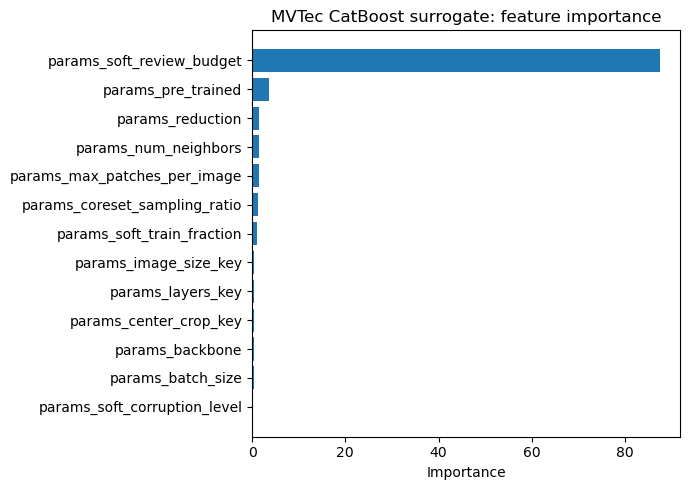

In [16]:
# ============================================================
# 16. CatBoost feature importance
# ============================================================

train_pool = Pool(
    X_train_cb,
    y_train,
    cat_features=cat_features_idx,
)

importance = cb.get_feature_importance(
    train_pool,
    type="PredictionValuesChange",
)

importance_df = (
    pd.DataFrame({
        "feature": X_train_cb.columns,
        "importance": importance,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df)

importance_path = TABLE_DIR / "mvtec_catboost_feature_importance.csv"
importance_df.to_csv(importance_path, index=False)

print("Saved:", importance_path)

top_k = min(15, len(importance_df))
plot_df = importance_df.head(top_k).iloc[::-1]

plt.figure(figsize=(7, 5))
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("Importance")
plt.title("MVTec CatBoost surrogate: feature importance")
plt.tight_layout()

plt.savefig(FIG_DIR / "mvtec_catboost_feature_importance.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "mvtec_catboost_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
# ============================================================
# 17. Save final surrogate model and metadata
# ============================================================

model_path = OUT_DIR / "mvtec_surrogate_catboost.cbm"
cb.save_model(str(model_path))

print("Saved model:", model_path)

metrics = {
    "dataset": str(DATA_PATH),
    "n_rows": int(len(df)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "target": TARGET,
    "features": FEATURES,
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "final_model": FINAL_MODEL,
    "rmse": float(rmse_cb),
    "mae": float(mae_cb),
    "r2": float(r2_cb),
    "fit_sec": float(cb_fit_sec),
    "best_iteration": int(cb.get_best_iteration()),
    "seed": SEED,
}

metadata_path = OUT_DIR / "mvtec_surrogate_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Saved metadata:", metadata_path)
print(json.dumps(metrics, indent=2))

Saved model: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_pkl_cfs_metadata/mvtec_surrogate_catboost.cbm
Saved metadata: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_pkl_cfs_metadata/mvtec_surrogate_metadata.json
{
  "dataset": "/home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv",
  "n_rows": 9976,
  "n_train": 7980,
  "n_test": 1996,
  "target": "value",
  "features": [
    "params_backbone",
    "params_batch_size",
    "params_center_crop_key",
    "params_image_size_key",
    "params_layers_key",
    "params_max_patches_per_image",
    "params_pre_trained",
    "params_reduction",
    "params_soft_corruption_level",
    "params_coreset_sampling_ratio",
    "params_num_neighbors",
    "params_soft_review_

In [18]:
# ============================================================
# 18. Save train/test split
# ============================================================

split_dir = OUT_DIR / "mvtec_train_test_split"
split_dir.mkdir(parents=True, exist_ok=True)

X_train.to_csv(split_dir / "X_train.csv", index=True)
X_test.to_csv(split_dir / "X_test.csv", index=True)
y_train.to_csv(split_dir / "y_train.csv", index=True)
y_test.to_csv(split_dir / "y_test.csv", index=True)

print("Saved train/test split to:", split_dir)

Saved train/test split to: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_pkl_cfs_metadata/mvtec_train_test_split


In [19]:
# ============================================================
# 19. Final summary for paper
# ============================================================

print("=== MVTec surrogate modelling summary ===")
print("Dataset:", DATA_PATH)
print("Rows:", len(df))
print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Final surrogate:", FINAL_MODEL)
print(f"RMSE: {rmse_cb:.6f}")
print(f"MAE:  {mae_cb:.6f}")
print(f"R2:   {r2_cb:.6f}")
print(f"Best iteration: {cb.get_best_iteration()}")

print("\nBest benchmark models:")
display(results_all.head(10))

print("\nTop feature importances:")
display(importance_df.head(10))

print("\nMain outputs:")
print("- Model:", model_path)
print("- Metadata:", metadata_path)
print("- Benchmark table:", results_all_path)
print("- Fidelity figure:", FIG_DIR / "mvtec_surrogate_fidelity.pdf")
print("- Feature importance:", importance_path)

=== MVTec surrogate modelling summary ===
Dataset: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_ready_dataset/mvtec_4class_patchcore_surrogate_dataset.csv
Rows: 9976
Train rows: 7980
Test rows: 1996
Final surrogate: CatBoost(native)
RMSE: 0.015053
MAE:  0.007954
R2:   0.995596
Best iteration: 2422

Best benchmark models:


,model,rmse,mae,r2,fit_sec,status,error
0,HistGBDT,0.014726,0.007935,0.995785,0.374586,ok,
1,CatBoost(native),0.015053,0.007954,0.995596,19.575429,ok,
2,XGBoost,0.015273,0.007893,0.995467,0.606794,ok,
3,GBDT,0.017022,0.009453,0.994369,0.647187,ok,
4,RandomForest,0.017585,0.008609,0.993990,0.486442,ok,
5,ExtraTrees,0.017592,0.008716,0.993985,0.656705,ok,
6,DecisionTree,0.024203,0.011624,0.988615,0.039608,ok,
7,AdaBoost,0.028218,0.022754,0.984525,4.070263,ok,
8,SVR(RBF),0.039203,0.031210,0.970130,3.026857,ok,
9,BayesianRidge,0.042565,0.034064,0.964788,0.033029,ok,



Top feature importances:


,feature,importance
0,params_soft_review_budget,87.392217
1,params_pre_trained,3.593353
2,params_reduction,1.480579
3,params_num_neighbors,1.470952
4,params_max_patches_per_image,1.432433
5,params_coreset_sampling_ratio,1.234341
6,params_soft_train_fraction,1.036139
7,params_image_size_key,0.499072
8,params_layers_key,0.468642
9,params_center_crop_key,0.458467



Main outputs:
- Model: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_pkl_cfs_metadata/mvtec_surrogate_catboost.cbm
- Metadata: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/surrogate_pkl_cfs_metadata/mvtec_surrogate_metadata.json
- Benchmark table: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_surrogate/mvtec_surrogate_model_benchmark_all.csv
- Fidelity figure: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/figures_surrogate/mvtec_surrogate_fidelity.pdf
- Feature importance: /home/jovyan/fast/Conversational-Counterfactual-Guidance-for-Operator-Centred-Hyperparameter-Optimisation/mvtec/tables_surrogate/mvtec_catboost_feature_importance.csv
